# 07 Summary: Status Check
One place for the status meeting: **model results**, **evidence of fit**, and **proposed fixes**.

The numbers are copied from each model notebook's results table. Every model uses the same data and the same season split:
train 2003-2016, validation 2017-2018, test 2019-2022.

| Model | Notebook | Status |
|---|---|---|
| Majority class | `03_majority_baseline` | done (train, validation, test) |
| Elo rating (tuned) | `04_elo_rating` | done (train, validation, test) |
| Logistic regression (tuned) | `05_logistic_regression` | done (train, validation); test reserved |
| Random forest | `06_random_forest` | done (train, validation); test reserved |

**Compare models on validation.** Notebooks 05 and 06 keep the test seasons untouched for the final comparison, so their test cells say "reserved".

### Step 1: results table

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# copied from each model notebook's results table (Step 6 in 03, Step 7 in 04, Step 7 in 05, Step 4 in 06)
# columns: model, notebook, split, accuracy, roc_auc, log_loss
rows = [
    ("Majority class", "03", "train",      0.5996, 0.5000, 0.6732),
    ("Majority class", "03", "validation", 0.5888, 0.5000, 0.6775),
    ("Majority class", "03", "test",       0.5544, 0.5000, 0.6914),
    ("Elo (tuned)",    "04", "train",      0.6695, 0.7101, 0.6052),
    ("Elo (tuned)",    "04", "validation", 0.6585, 0.6953, 0.6182),
    ("Elo (tuned)",    "04", "test",       0.6310, 0.6705, 0.6465),
    ("Logistic regression (tuned)", "05", "train",      0.6743, 0.7198, 0.5983),
    ("Logistic regression (tuned)", "05", "validation", 0.6658, 0.7029, 0.6142),
    ("Logistic regression (tuned)", "05", "test",       np.nan, np.nan, np.nan),   # reserved for the final
    ("Random forest", "06", "train",      0.7377, 0.8101, 0.5356),
    ("Random forest", "06", "validation", 0.6654, 0.7023, 0.6143),
    ("Random forest", "06", "test",       np.nan, np.nan, np.nan),                 # reserved for the final
]
results = pd.DataFrame(rows, columns=["model", "notebook", "split", "accuracy", "roc_auc", "log_loss"])

models = list(dict.fromkeys(results["model"]))
splits = ["train", "validation", "test"]
table = results.pivot(index="model", columns="split", values=["accuracy", "roc_auc", "log_loss"])
table = table.reindex(index=models, columns=pd.MultiIndex.from_product([["accuracy", "roc_auc", "log_loss"], splits]))
table.round(4).astype(object).where(table.notna(), "reserved")

accuracy                      roc_auc             \
                               train validation      test   train validation   
model                                                                          
Majority class                0.5996     0.5888    0.5544     0.5        0.5   
Elo (tuned)                   0.6695     0.6585     0.631  0.7101     0.6953   
Logistic regression (tuned)   0.6743     0.6658  reserved  0.7198     0.7029   
Random forest                 0.7377     0.6654  reserved  0.8101     0.7023   

                                      log_loss                       
                                 test    train validation      test  
model                                                                
Majority class                    0.5   0.6732     0.6775    0.6914  
Elo (tuned)                    0.6705   0.6052     0.6182    0.6465  
Logistic regression (tuned)  reserved   0.5983     0.6142  reserved  
Random forest                reserved   0.5356     0.6143  reserved

### Step 2: accuracy from train to validation to test
A big drop from train to validation means **overfitting**. Low scores everywhere with a small drop means **underfitting**.

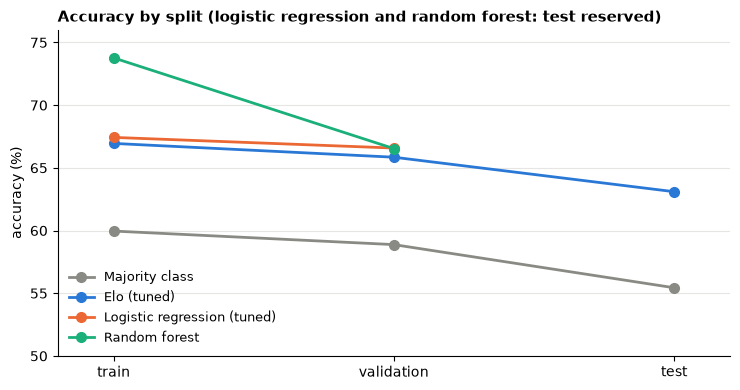

In [2]:
done = results.dropna(subset=["accuracy"])
done_models = list(dict.fromkeys(done["model"]))
colors = ["#8a8a85", "#2a78d6", "#eb6834", "#1baf7a"]   # one fixed color per model, in table order

fig, ax = plt.subplots(figsize=(7.5, 4))
for m in done_models:
    color = colors[models.index(m)]
    d = done[done["model"] == m].set_index("split").reindex(splits)["accuracy"].dropna() * 100   # test may be reserved
    xs = [splits.index(s) for s in d.index]
    ax.plot(xs, d.values, color=color, lw=2, marker="o", ms=7, label=m)   # exact values are in the table above
ax.set_xticks(range(len(splits))); ax.set_xticklabels(splits); ax.set_xlim(-0.2, 2.2)
ax.set_ylim(50, 76); ax.set_ylabel("accuracy (%)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e5e1")
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.set_title("Accuracy by split (logistic regression and random forest: test reserved)", loc="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

### Step 3: findings so far

**Majority class (notebook 03)**
- Always predicts a home win. Accuracy is exactly the home win rate of each period: 59.96% train, 58.88% validation, 55.44% test.
- Recall is 1.0 and precision equals accuracy because it never predicts an away win. ROC-AUC is 0.5 because every game gets the same probability, so it cannot rank games.
- Fit: it learns one number, so it cannot overfit or underfit in a useful sense. It is the floor every model must beat.
- Test is lower only because the home win rate fell to about 55% in the COVID seasons (2019-2021).

**Elo rating (notebook 04)**
- About 7 points above the majority class on every split: 66.95% train, 65.85% validation, 63.10% test (ROC-AUC 0.71 / 0.70 / 0.67).
- Tuned with forward-chaining folds (2012-2016): K = 20, home advantage = 75, carryover = 0.75. Tuning barely matters: the default setting is only 0.3 to 0.9 points worse, and the scores change more between seasons than between settings.
- Fit: **no overfitting**. Train and validation are close (66.95% vs 65.85%, log loss 0.6052 vs 0.6182). With 3 settings it cannot memorize the data.
- If anything it **underfits**: one strength number per team cannot use rest days or recent form.
- On test it over-predicts home wins (the calibration plot falls below the diagonal), because the COVID seasons had a weaker home edge than Elo expects.

**Logistic regression (notebook 05)**
- Uses all 76 pre-game features (missing values filled with training medians, features standardized inside a pipeline).
- Tuned with the same forward-chaining folds: C = 0.01 (strong regularization), mean fold log loss 0.6028. Tuning barely matters: every C from 0.001 to 100 is within 0.001.
- 67.43% train and 66.58% validation (ROC-AUC 0.72 / 0.70, log loss 0.5983 / 0.6142). That is 7.7 points above majority and 0.7 points above Elo on validation.
- Fit: **good fit, no overfitting**. Train and validation differ by only 0.85 points. But it barely beats Elo alone, so most of the extra features repeat what Elo already knows about team strength. A linear model may be **slightly underfitting**.

**Random forest (notebook 06)**
- 100 trees, max depth 10, at least 20 games per leaf (settings from earlier runs, not tuned with the folds in the notebook).
- 73.77% train but 66.54% validation (ROC-AUC 0.81 / 0.70, log loss 0.5356 / 0.6143).
- Fit: **overfitting**. Train is 7.2 points above validation, and train log loss (0.5356) is much lower than validation (0.6143). The extra flexibility memorizes the training seasons without helping on new seasons: its validation score is the same as logistic regression's.

**Overall:** three very different models (Elo, logistic regression, random forest) all land at about 66% on validation. The limit is probably the information in the features, not the choice of model.

### Step 4: proposed fixes for overfitting / underfitting
**Random forest (overfitting)**
- Tune `max_depth`, `min_samples_leaf` and `max_features` with the forward-chaining folds, and plot train vs validation accuracy as depth grows to pick the point where validation stops improving.
- Try shallower trees, larger leaves and fewer features per split. Adding more trees does not fix overfitting.

**Logistic regression and Elo (slight underfitting)**
- Better features, not a different model: player availability from `games_details` (who played, minutes), travel and schedule density, and interactions such as rest days x back-to-back.
- Use the tuned Elo settings (home advantage 75) when building the Elo features in notebook 02. The shared table still uses the default (100).
- Try gradient boosting, which can capture interactions, while watching for the same overfitting as the random forest.

**All models**
- Drop `DIFF_ST_W_PCT`, an exact duplicate of `DIFF_SEASON_W_PCT` (correlation 1.00).
- Use the same forward-chaining tuning everywhere, and score every model on the test seasons once, at the end, for the final comparison.

### Step 5: remaining work plan

**Tasks still to complete**
- Apply the professor's feedback from this meeting.
- Fix the random forest: tune it with the forward-chaining folds and add the train vs validation curve over tree depth.
- Clean the shared table: drop the duplicate `DIFF_ST_W_PCT` and rebuild the Elo features with the tuned setting (home advantage 75) in notebook 02.
- Score every model on the test seasons once, at the end, and build the final comparison.
- Final notebooks, slides for the 20-minute presentation, and submission.

**Additional models**
- KNN and a decision tree.
- SVM with a linear and a Gaussian (RBF) kernel.
- Gradient boosting: XGBoost and CatBoost.
- Stacking or voting ensemble of the best models.
- Neural networks in Keras: a small network and a deeper one.

**Evaluations and improvements**
- Same forward-chaining tuning and the same six metrics (accuracy, precision, recall, F1, ROC-AUC, log loss) for every model.
- Train vs validation comparison for each model to check over/underfitting.
- Calibration plots for the best models.

**Further analysis**
- Feature importance (random forest importances and permutation importance): which pre-game signals matter most.
- Results by season, especially the COVID seasons (2019-2021) with the weaker home edge.
- Optional: player availability features from `games_details.csv` (who played, minutes), the most likely way to move past about 66%.

**Timeline** (proposed; final presentation dates to confirm with the professor)

| When | Work |
|---|---|
| Nov 18-22 | Apply feedback; fix and tune the random forest; clean the shared table |
| Nov 23-25 | KNN, decision tree, SVM (linear and RBF) |
| Nov 26-29 (Thanksgiving break) | XGBoost, CatBoost, stacking/voting, neural networks |
| Nov 29-30 | Test-season evaluation of all models, final comparison, feature importance, conclusions, slides |
| Nov 30 - Dec 2 | Final presentation; submit notebooks before our presentation time |